## Forecasting Stock Prices with LSTM

**Objective**  
To visualize and analyze stock price time series data, extract trends and seasonality, and forecast future stock prices using an LSTM model.

**Dataset**  
`Dataset Source:` Yahoo Finance  
`Dataset:` Daily stock prices for Apple Inc. (AAPL) over the last 5 years.

In [19]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

**Download the dataset**

In [20]:
df = yf.download('AAPL', start='2018-01-01', end='2023-01-01')
df.reset_index(inplace=True)

[*********************100%***********************]  1 of 1 completed


In [24]:
df.head()

Price,Date,Close,High,Low,Open,Volume
Ticker,,AAPL,AAPL,AAPL,AAPL,AAPL
0,2018-01-02,40.232376,40.241720,39.531708,39.741910,102223600
1,2018-01-03,40.225368,40.767220,40.162311,40.295436,118071600
2,2018-01-04,40.412209,40.514974,40.190331,40.297765,89738400
3,2018-01-05,40.872322,40.958737,40.416888,40.507975,94640000
4,2018-01-08,40.720516,41.014796,40.622419,40.720516,82271200


**Data Preprocessing**  
Convert the `Date` column to datetime format and handle any missing values.

In [25]:
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

In [26]:
# Handle missing values by forward filling
df = df.ffill()

In [27]:
df.isnull().sum()

Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64

**Data Visualization**  
Visualize the closing prices over time and include moving averages.

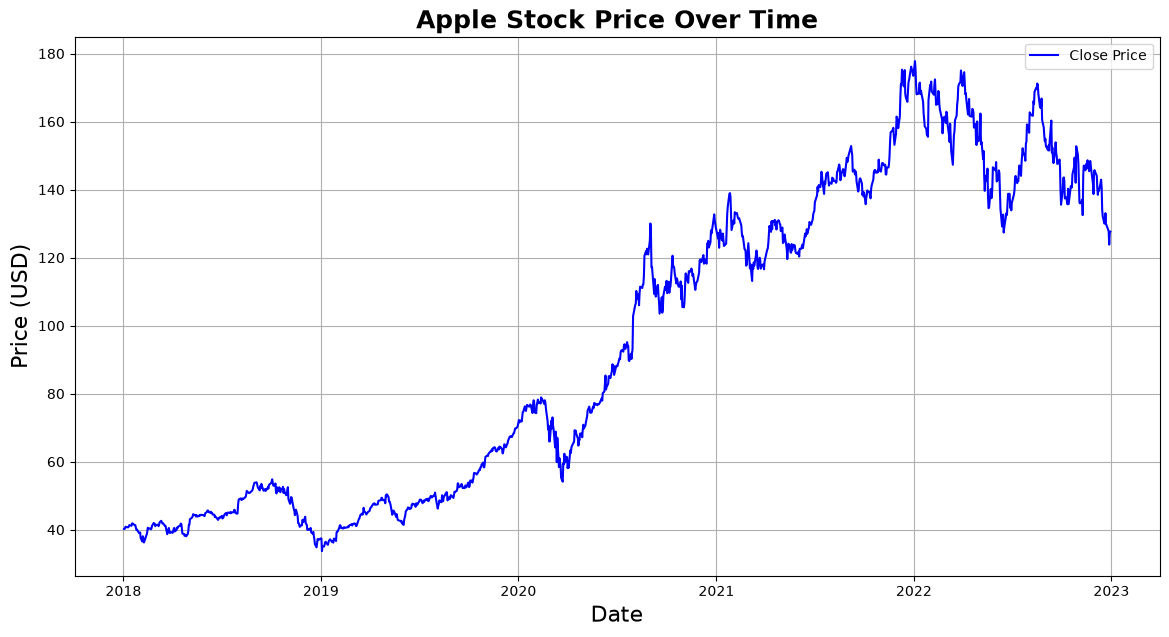

In [28]:
plt.figure(figsize=(14, 7))
plt.plot(df['Close'], label='Close Price', color='blue')
plt.title('Apple Stock Price Over Time', fontweight='bold', fontsize=18)
plt.xlabel('Date', fontsize=16)
plt.ylabel('Price (USD)', fontsize=16)
plt.grid()
plt.legend()
plt.show()

**Feature Engineering**  
Create features suitable for LSTM input.

In [29]:
# Normalize the dataset
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df['Close'].values.reshape(-1, 1))

In [30]:
scaled_data

array([[0.045284  ],
       [0.04523536],
       [0.04653216],
       ...,
       [0.62550506],
       [0.64984885],
       [0.65203068]], shape=(1259, 1))

In [31]:
# Create training data
training_data_len = int(np.ceil(0.8 * len(scaled_data)))

# Create the training dataset
train_data = scaled_data[0:training_data_len]

# Split the data into X_train and y_train
x_train = []
y_train = []

for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])

x_train, y_train = np.array(x_train), np.array(y_train)

# Reshape the data
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))

**Build the LSTM Model**  
Construct and compile the LSTM model.

In [32]:
model = Sequential()
model.add(LSTM(50, return_sequences=True, input_shape=(x_train.shape[1], 1)))
model.add(Dropout(0.2))
model.add(LSTM(50, return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(25))
model.add(Dense(1))  # Output layer

model.compile(optimizer='adam', loss='mean_squared_error')

c:\Users\PC\anaconda3\envs\hccda\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


**Train the Model**  
Fit the model to the training data.

In [33]:
model.fit(x_train, y_train, batch_size=1, epochs=10)

Epoch 1/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 36s 32ms/step - loss: 0.0058
Epoch 2/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 35s 32ms/step - loss: 0.0023
Epoch 3/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 31s 32ms/step - loss: 0.0017
Epoch 4/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 32s 33ms/step - loss: 0.0021
Epoch 5/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 30s 32ms/step - loss: 0.0021
Epoch 6/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 28s 30ms/step - loss: 0.0020
Epoch 7/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 32s 34ms/step - loss: 0.0018
Epoch 8/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 46s 49ms/step - loss: 0.0016
Epoch 9/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 46s 48ms/step - loss: 0.0018
Epoch 10/10
948/948 ━━━━━━━━━━━━━━━━━━━━ 58s 61ms/step - loss: 0.0016


**Create Testing Dataset**  
Prepare the test dataset to evaluate the model.

In [34]:
test_data = scaled_data[training_data_len - 60:]

x_test = []
y_test = df['Close'][training_data_len:].values

for i in range(60, len(test_data)):
    x_test.append(test_data[i-60:i, 0])

x_test = np.array(x_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

**Make Predictions**  
Use the model to predict future prices.

In [35]:
predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)  # Inverse scaling

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 203ms/step


**Visualize Predictions**  
Compare the predicted prices with actual prices.

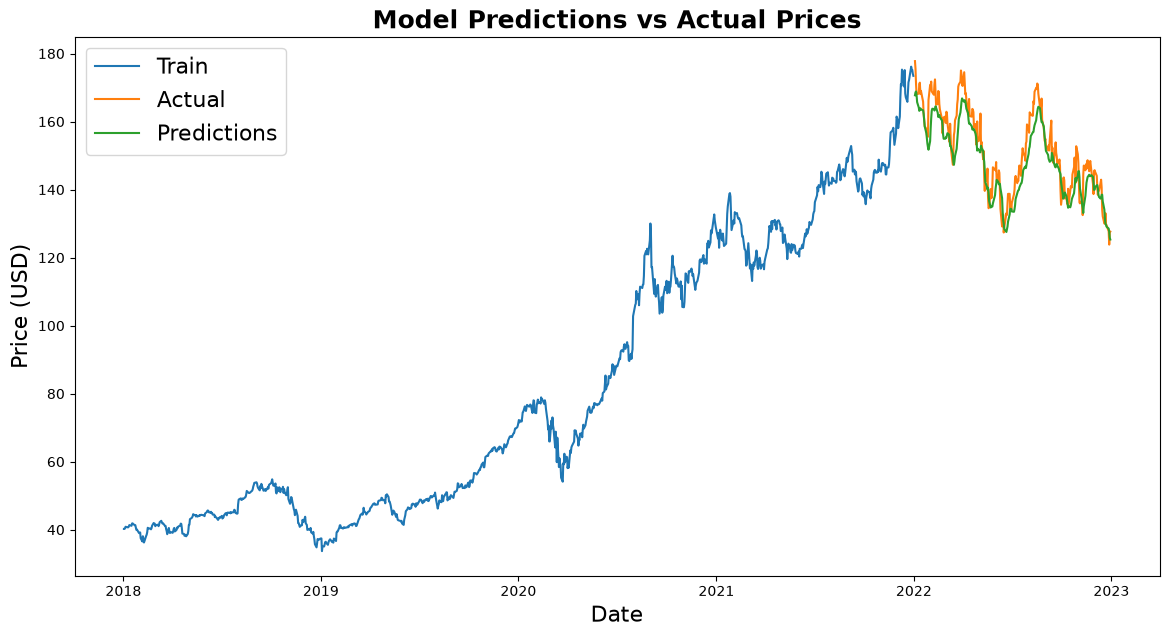

In [37]:
train = df[:training_data_len]
valid = df[training_data_len:]
valid['Predictions'] = predictions

plt.figure(figsize=(14, 7))
plt.title('Model Predictions vs Actual Prices', fontsize=18, fontweight='bold')
plt.xlabel('Date', fontsize=16)
plt.ylabel('Price (USD)', fontsize=16)
plt.plot(train['Close'])
plt.plot(valid[['Close', 'Predictions']])
plt.legend(['Train', 'Actual', 'Predictions'], fontsize=16)
plt.show()

---